# Linear algebraic study of indices

## Part 1: proving the mean I index and mean I' index aren't represented by the daughter-number basis

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add the parent directory to Python path so we can import from src
import sys
import os
parent_dir = os.path.dirname(os.getcwd())
sys.path.append(parent_dir)

from src.tree_bstats.tree import Tree
from src.tree_bstats.unlabelled_tree import UnlabelledTree
import src.tree_bstats.indices as indices

In [2]:
# Generate all trees of size n=7
n = 7
treeBuilder = UnlabelledTree(n)
_, daughterNumbers, balanceIndices, weights = treeBuilder.get_data(n)

Trees generated with counts  [1, 1, 1, 2, 3, 6, 11]


In [3]:
# Get the Mean I and Mean I' index values
labels = treeBuilder.balance_index_names
meanI_idx = labels.index('Mean I index')
meanI_prime_idx = labels.index('Mean I\' index')


In [4]:
balanceIndices = np.array(balanceIndices)
meanI = balanceIndices[:, meanI_idx]
meanI_prime = balanceIndices[:, meanI_prime_idx]

In [5]:
daughterNumbers = np.array(daughterNumbers)
daughterNumbers

array([[1., 1., 1., 1., 1., 1., 0., 0., 0., 0., 0., 0.],
       [2., 0., 0., 1., 1., 1., 1., 0., 0., 0., 0., 0.],
       [2., 1., 0., 0., 1., 1., 0., 1., 0., 0., 0., 0.],
       [2., 1., 1., 0., 0., 1., 0., 0., 1., 0., 0., 0.],
       [3., 0., 0., 0., 0., 1., 1., 0., 1., 0., 0., 0.],
       [2., 2., 0., 0., 0., 1., 0., 0., 0., 0., 1., 0.],
       [2., 1., 1., 1., 0., 0., 0., 0., 0., 1., 0., 0.],
       [3., 0., 0., 1., 0., 0., 1., 0., 0., 1., 0., 0.],
       [3., 1., 0., 0., 0., 0., 0., 1., 0., 1., 0., 0.],
       [2., 2., 1., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
       [3., 1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 1.]])

In [6]:
# Print meanI and mean I' values as rational numbers
from sympy import Rational
meanI_rational = [Rational(x).limit_denominator() for x in meanI]
meanI_prime_rational = [Rational(x).limit_denominator() for x in meanI_prime]

# print
print("Mean I index values:")
print(meanI_rational)

print("Mean I' index values:")
print(meanI_prime_rational)

Mean I index values:
[1, 3/4, 5/6, 5/6, 1/2, 1/2, 8/9, 5/9, 7/12, 2/3, 1/6]
Mean I' index values:
[43/48, 17/24, 7/9, 13/18, 17/36, 1/2, 29/36, 5/9, 7/12, 13/24, 1/6]


In [7]:
# Study the equation Ax = b, where A is the daughterNumbers matrix and b is the balance indices vector
A = daughterNumbers
b = meanI

# Find the reduced row echelon form of A and the augmented matrix [A | b]
from sympy import Matrix
A_matrix = Matrix(A)
b_matrix = Matrix(b)
augmented_matrix = A_matrix.row_join(b_matrix)
rref_matrix, pivot_columns = augmented_matrix.rref()

# Display the reduced row echelon form-write in fractions for better readability
from sympy import Rational
rref_matrix_fraction = rref_matrix.applyfunc(lambda x: Rational(x).limit_denominator())
print("Reduced Row Echelon Form:")
rref_matrix_fraction

Reduced Row Echelon Form:


Matrix([
[1, 0, 0, 0, 0, 0, 0,  3/7,  1/7,  3/7, -1/7, -1/7, 0],
[0, 1, 0, 0, 0, 0, 0, -2/7, -3/7, -2/7,  3/7,  3/7, 0],
[0, 0, 1, 0, 0, 0, 0, -2/7,  4/7, -2/7, -4/7,  3/7, 0],
[0, 0, 0, 1, 0, 0, 0, -2/7, -3/7,  5/7,  3/7, -4/7, 0],
[0, 0, 0, 0, 1, 0, 0,  5/7, -3/7, -2/7, -4/7,  3/7, 0],
[0, 0, 0, 0, 0, 1, 0, -2/7,  4/7, -2/7,  3/7, -4/7, 0],
[0, 0, 0, 0, 0, 0, 1,   -1,    0,   -1,    0,    1, 0],
[0, 0, 0, 0, 0, 0, 0,    0,    0,    0,    0,    0, 1],
[0, 0, 0, 0, 0, 0, 0,    0,    0,    0,    0,    0, 0],
[0, 0, 0, 0, 0, 0, 0,    0,    0,    0,    0,    0, 0],
[0, 0, 0, 0, 0, 0, 0,    0,    0,    0,    0,    0, 0]])

In [8]:
# Do the same thing for the Mean I' index
b_prime = meanI_prime
augmented_matrix_prime = A_matrix.row_join(Matrix(b_prime))
rref_matrix_prime, pivot_columns_prime = augmented_matrix_prime.rref()
# Display the reduced row echelon form for Mean I'
rref_matrix_prime_fraction = rref_matrix_prime.applyfunc(lambda x: Rational(x).limit_denominator())
print("Reduced Row Echelon Form for Mean I':")
rref_matrix_prime_fraction

Reduced Row Echelon Form for Mean I':


Matrix([
[1, 0, 0, 0, 0, 0, 0,  3/7,  1/7,  3/7, -1/7, -1/7, 0],
[0, 1, 0, 0, 0, 0, 0, -2/7, -3/7, -2/7,  3/7,  3/7, 0],
[0, 0, 1, 0, 0, 0, 0, -2/7,  4/7, -2/7, -4/7,  3/7, 0],
[0, 0, 0, 1, 0, 0, 0, -2/7, -3/7,  5/7,  3/7, -4/7, 0],
[0, 0, 0, 0, 1, 0, 0,  5/7, -3/7, -2/7, -4/7,  3/7, 0],
[0, 0, 0, 0, 0, 1, 0, -2/7,  4/7, -2/7,  3/7, -4/7, 0],
[0, 0, 0, 0, 0, 0, 1,   -1,    0,   -1,    0,    1, 0],
[0, 0, 0, 0, 0, 0, 0,    0,    0,    0,    0,    0, 1],
[0, 0, 0, 0, 0, 0, 0,    0,    0,    0,    0,    0, 0],
[0, 0, 0, 0, 0, 0, 0,    0,    0,    0,    0,    0, 0],
[0, 0, 0, 0, 0, 0, 0,    0,    0,    0,    0,    0, 0]])

## The fact that these reduced row echelon forms have a row with all 0's except a 1 in the final column proves that the linear system has no solution

# Part 2: Using least squares to approximate a solution to all balance indices under the clade-number basis

In [9]:
import scipy.linalg as la
import src.tree_bstats.indices as indices
import pandas as pd

In [10]:
# First, we generate all the trees up to size n = 16
n = 16
trees = UnlabelledTree(n)

Trees generated with counts  [1, 1, 1, 2, 3, 6, 11, 23, 46, 98, 207, 451, 983, 2179, 4850, 10905]


In [11]:
# Because it has such poorly-behaved values, we remove the Colijn-Plazzotta rank from the list of balance indices
all_index_names = trees.balance_index_names
cp_idx = trees.balance_index_names.index('Colijn-Plazzotta rank')

index_names = [name for i, name in enumerate(all_index_names) if i != cp_idx]

In [15]:
# Next, for all k=4,...,16, we use least squares to find approximate solution and track residual error for each index

k0 = 4
clade_residuals = np.zeros((n-k0 + 1, len(index_names)))
clade_regression_results = {name: [] for name in index_names}

for k in range(k0, n+1):

    clade_numbers, _, balance_indices, weights = trees.get_data(k)

    clade_numbers = np.array(clade_numbers)

    # Remove the last column of the clade_numbers (since this is redundant and always equal to 1)
    # clade_numbers = clade_numbers[:, :-1]
    balance_indices = pd.DataFrame(balance_indices, columns=all_index_names)
    # drop Colijn-Plazzatto index
    balance_indices = balance_indices.drop(columns=['Colijn-Plazzotta rank'])
    weights = np.array(weights)

    # weight the data by weights before performing least squares
    W = np.sqrt(np.diag(weights))
    Bw = np.dot(W, balance_indices.values)
    Cw = np.dot(W, clade_numbers)

    for i in range(len(index_names)):
        # Project each balance index onto the clade number axis
        X = la.lstsq(Cw, Bw[:, i])[0]
        clade_regression_results[index_names[i]].append(X)
        B_proj = np.dot(Cw, X)
        residual = np.sum((B_proj - Bw[:, i])**2)

        # To compare residuals across indices, we divide by the magnitude of the balance index
        residual /= la.norm(Bw[:, i])
        clade_residuals[k-k0, i] = residual


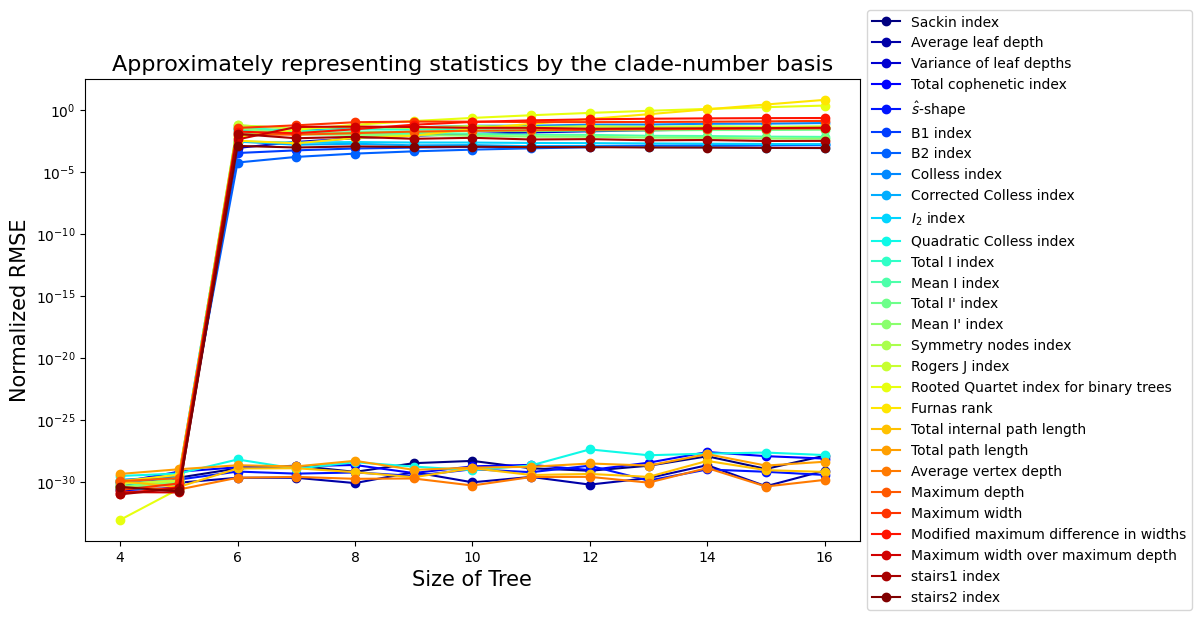

In [16]:
# Now plot the residuals
colors = plt.cm.jet(np.linspace(0,1,len(index_names)))

plt.figure(figsize=(10, 6))
for i in range(len(index_names)):
    plt.semilogy(range(k0, n+1), clade_residuals[:, i], 'o-', label=index_names[i], color=colors[i])
plt.xlabel('Size of Tree', fontsize = 15)
plt.ylabel('Normalized RMSE', fontsize = 15)
plt.legend(index_names)
# Move legend to far right
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.title('Approximately representing statistics by the clade-number basis', fontsize = 16)
plt.show()

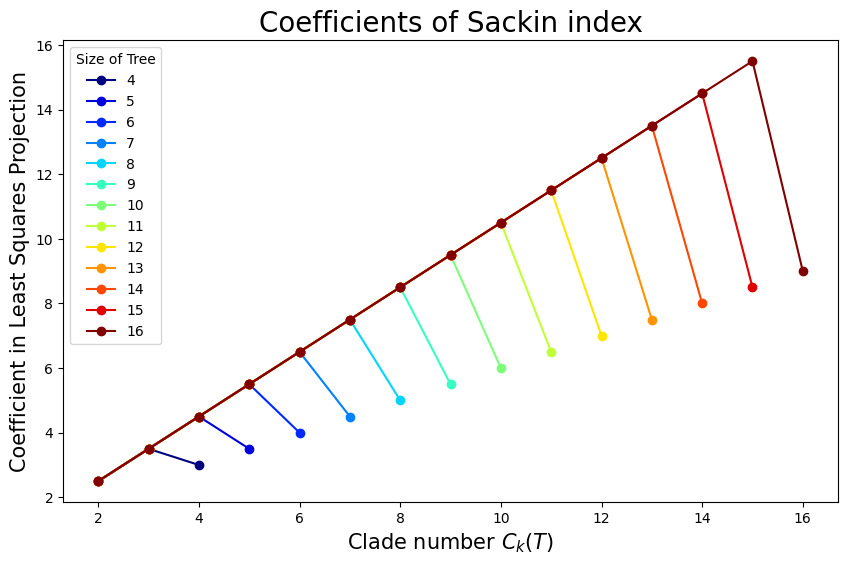

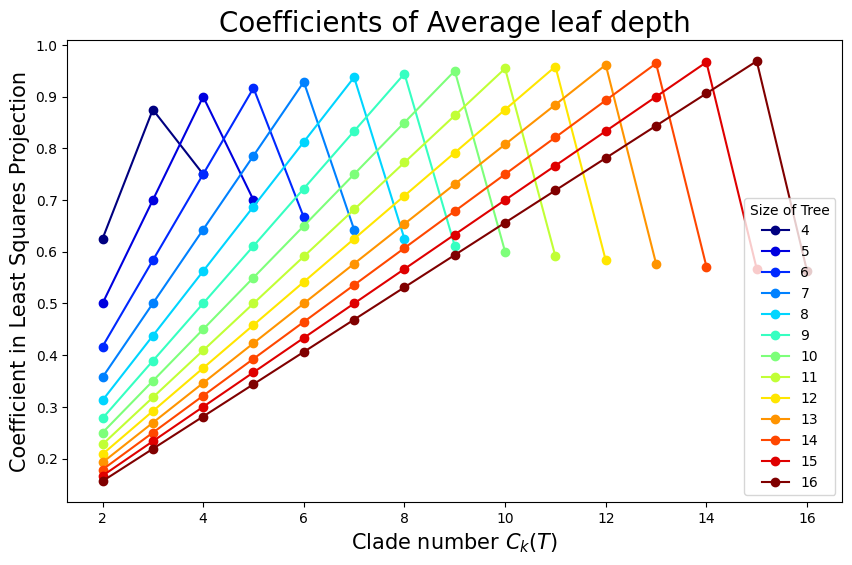

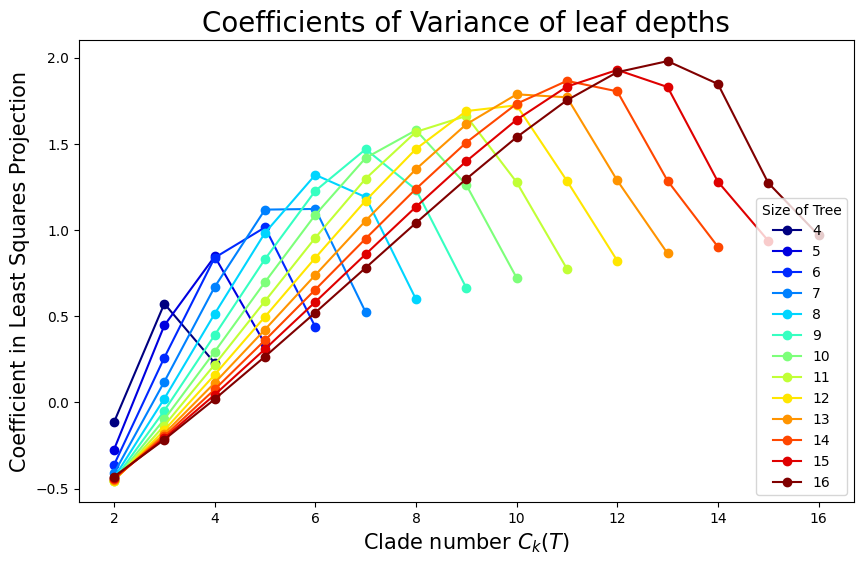

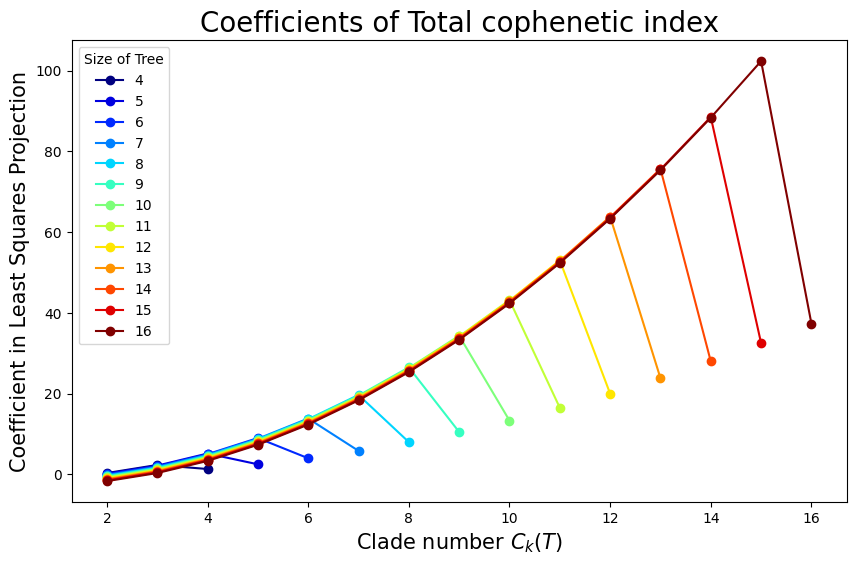

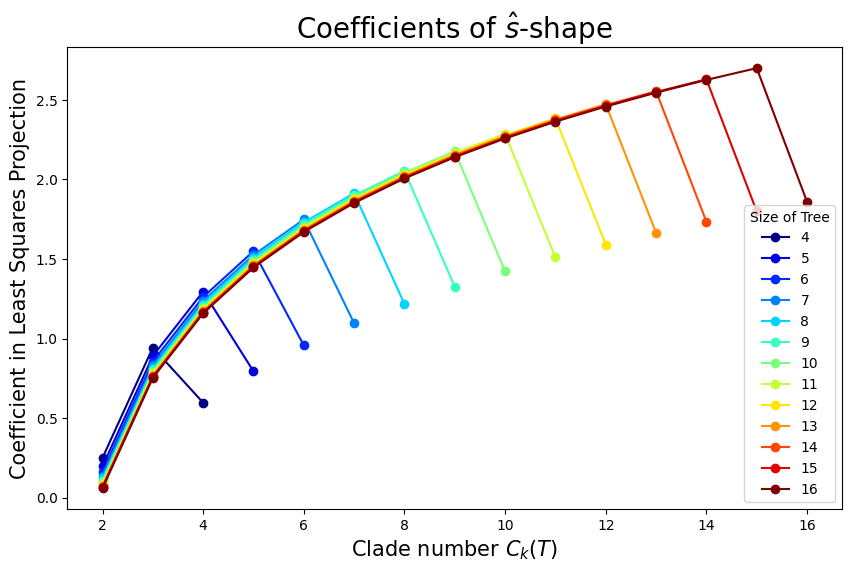

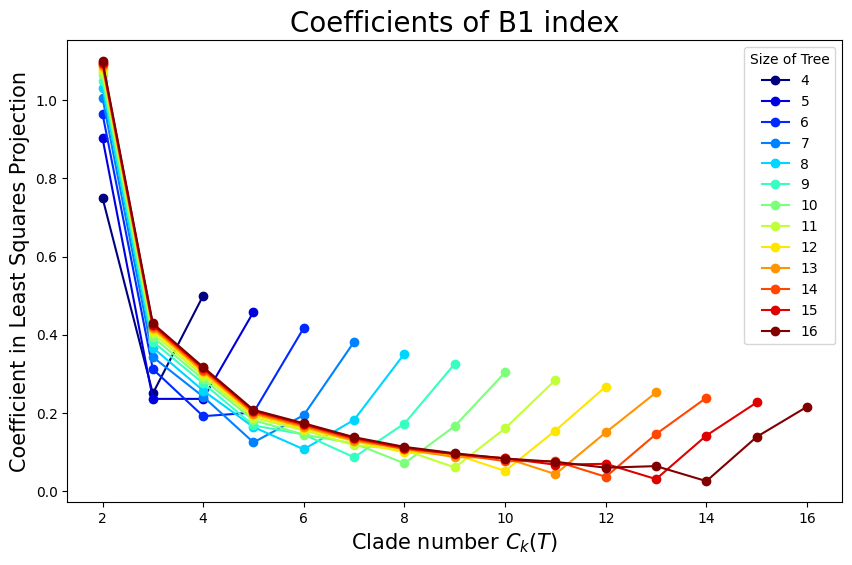

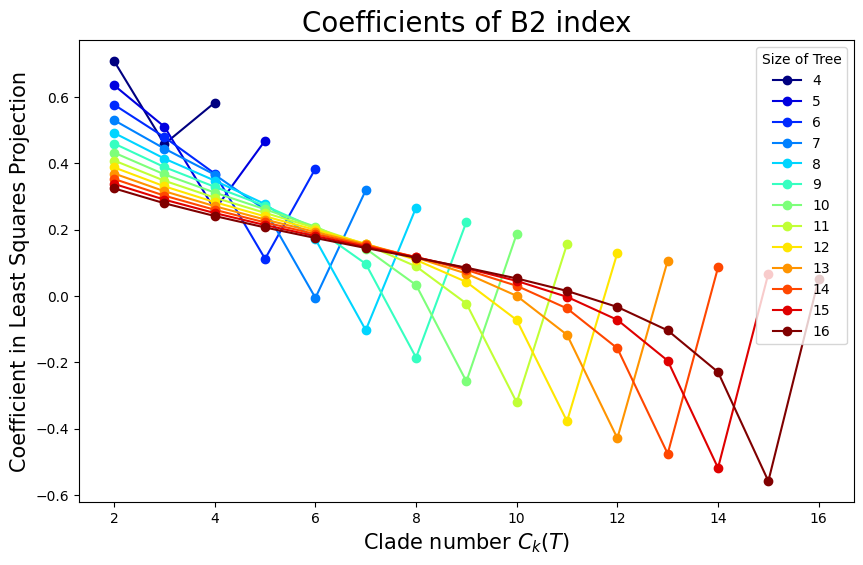

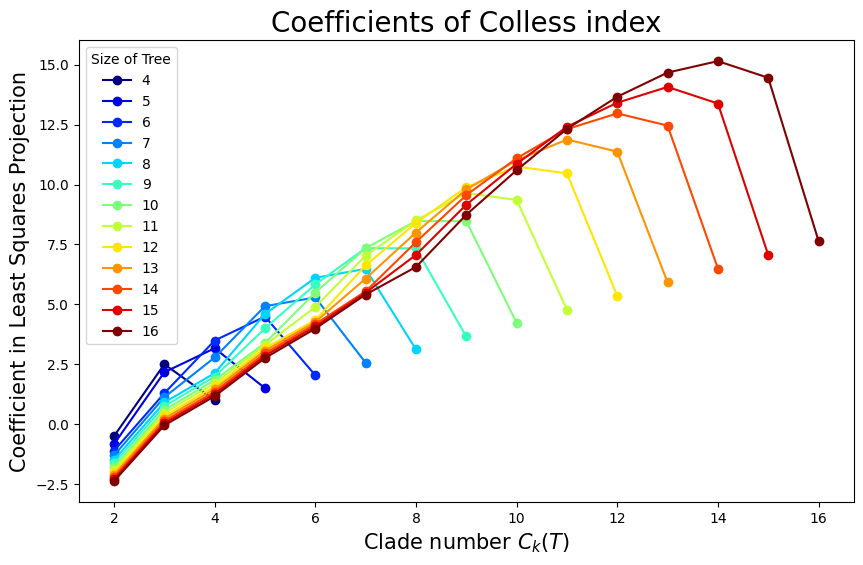

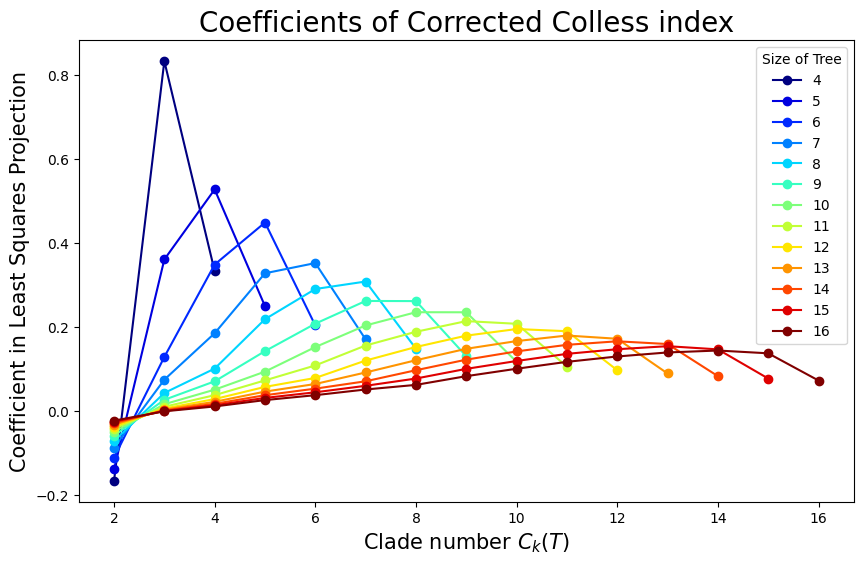

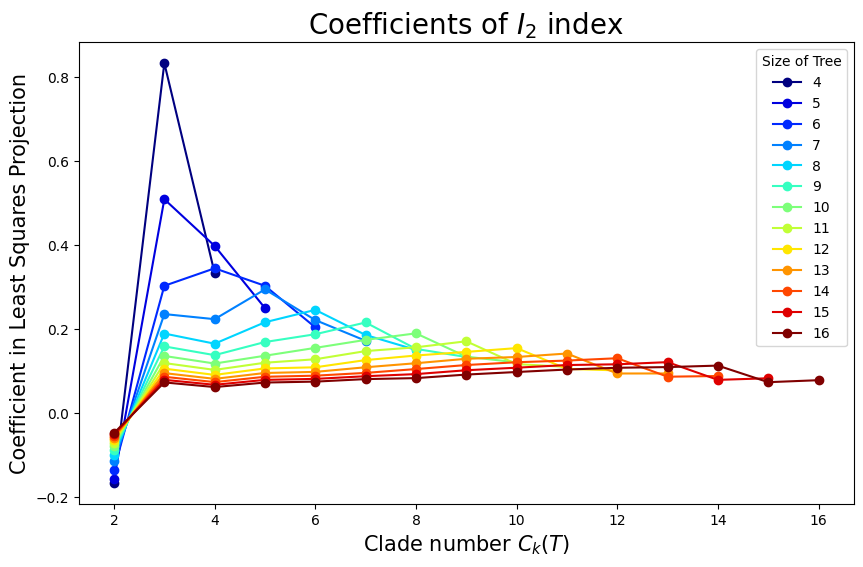

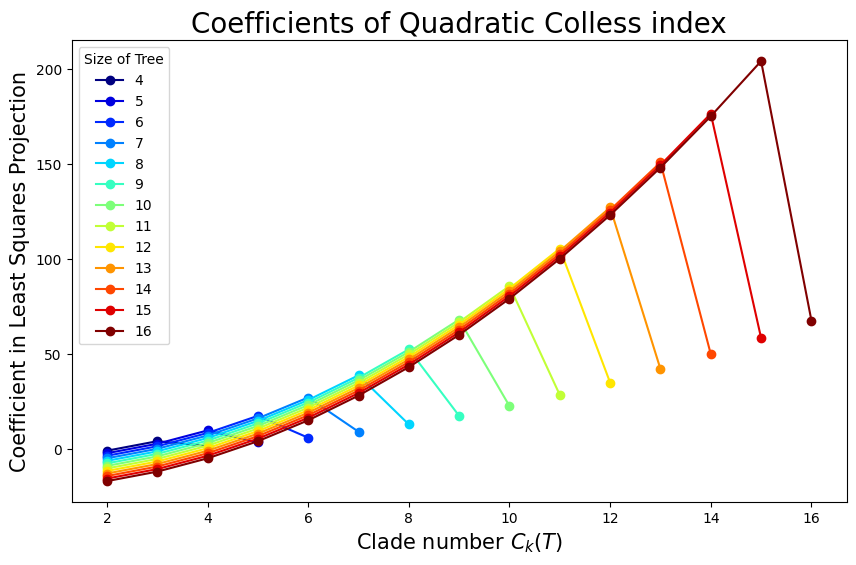

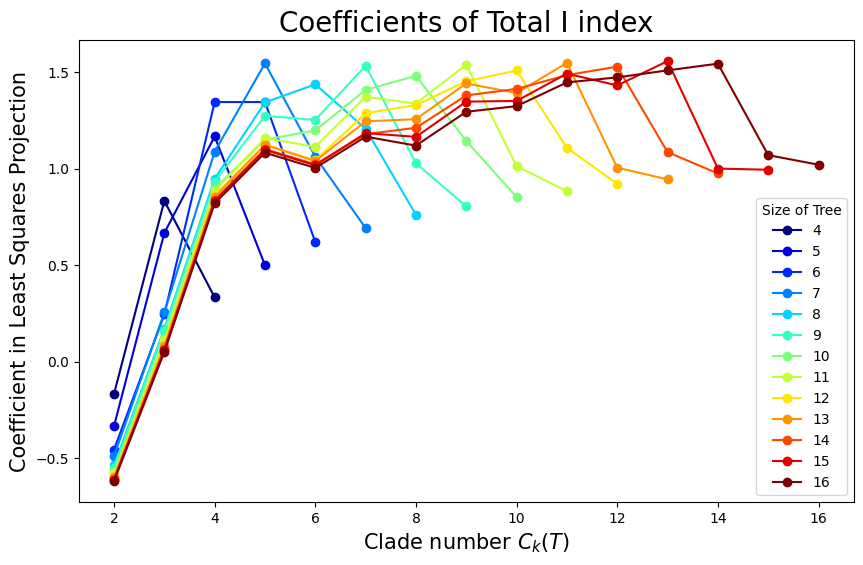

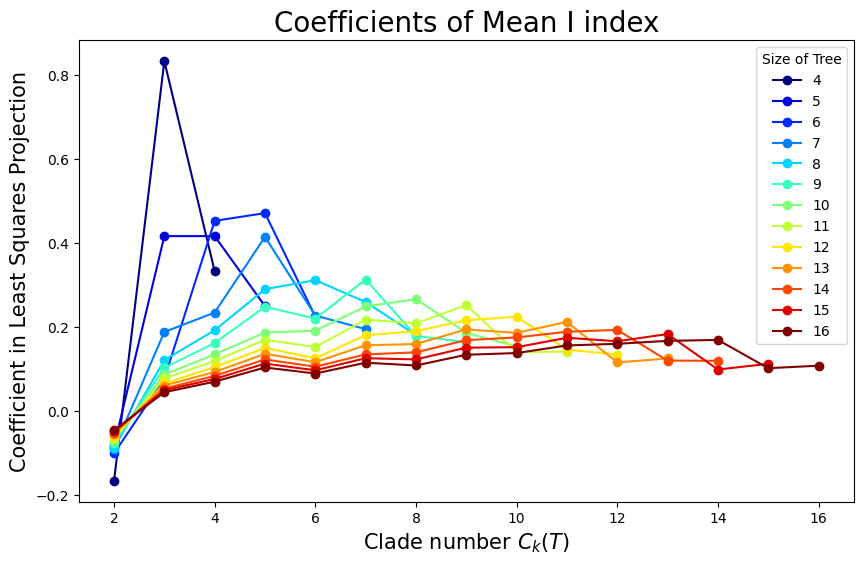

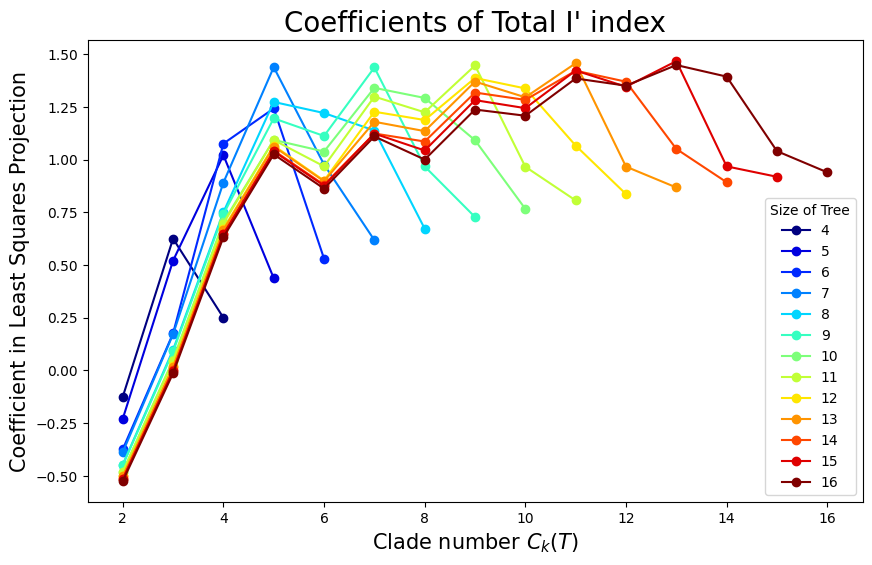

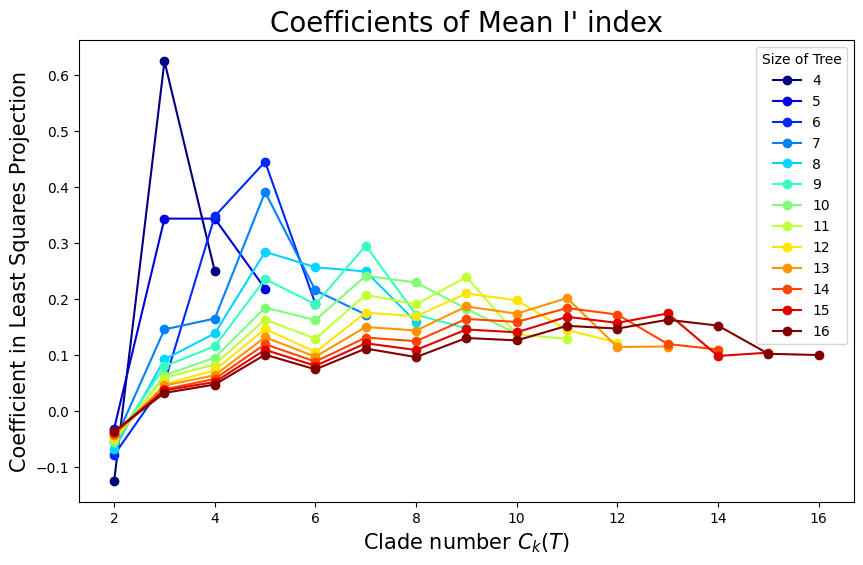

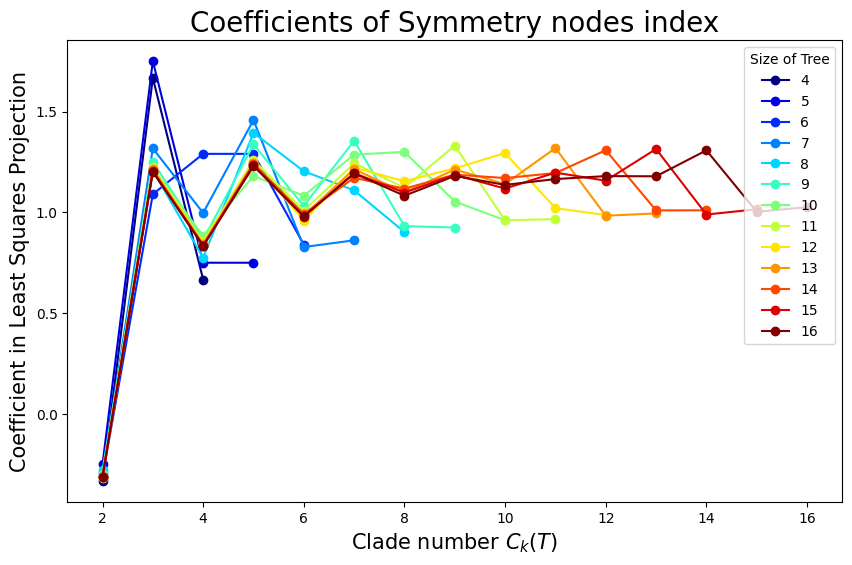

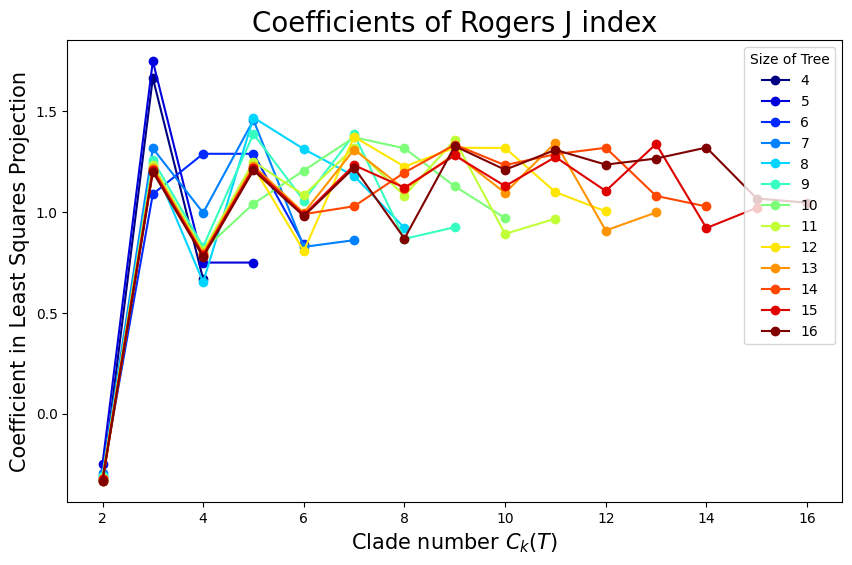

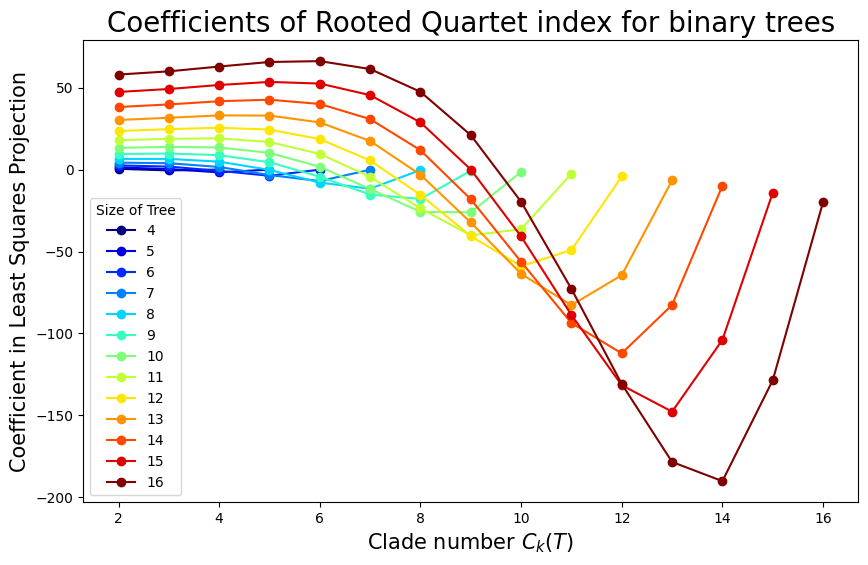

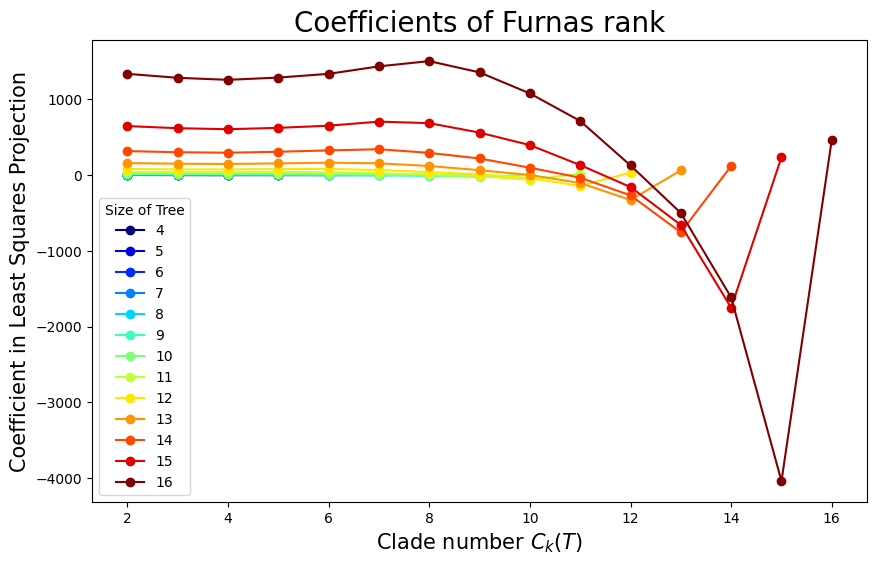

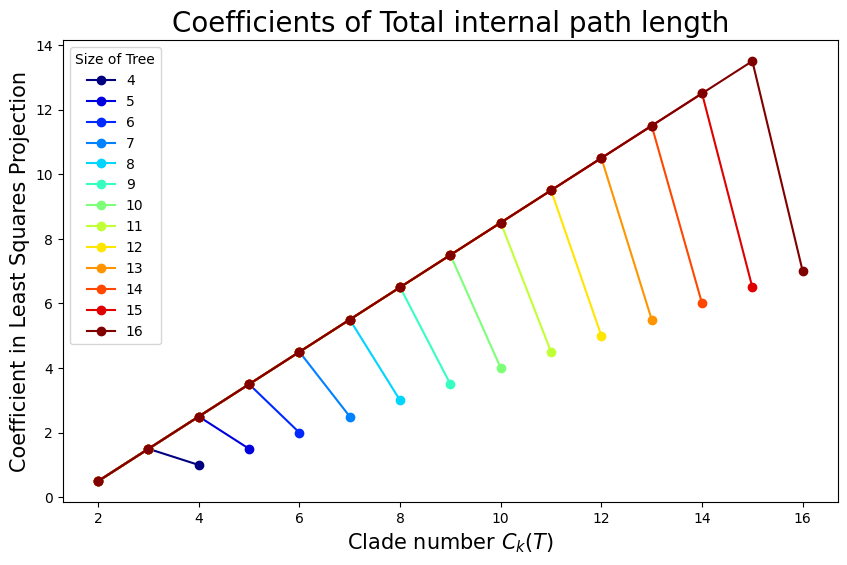

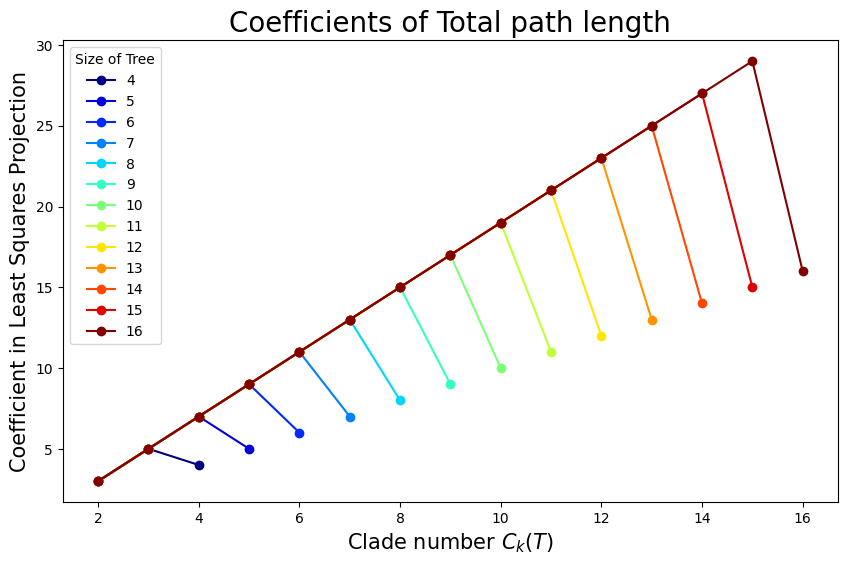

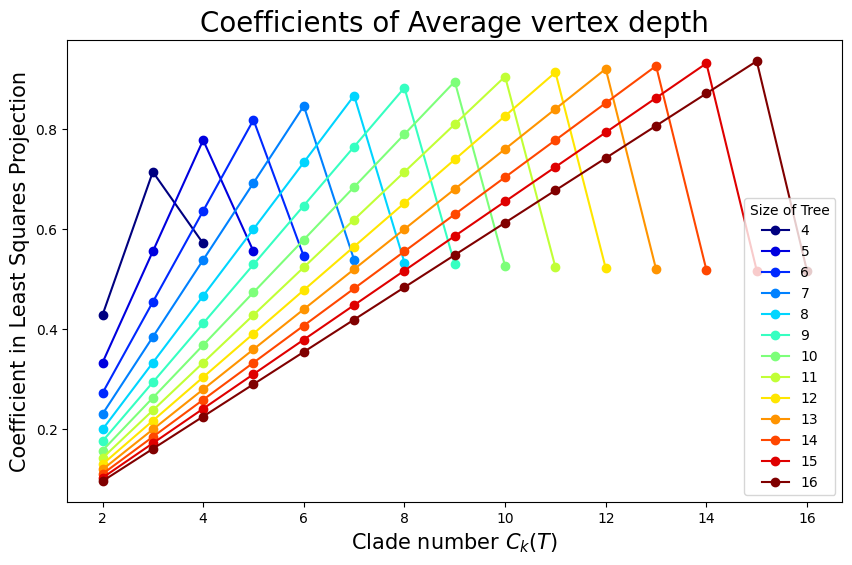

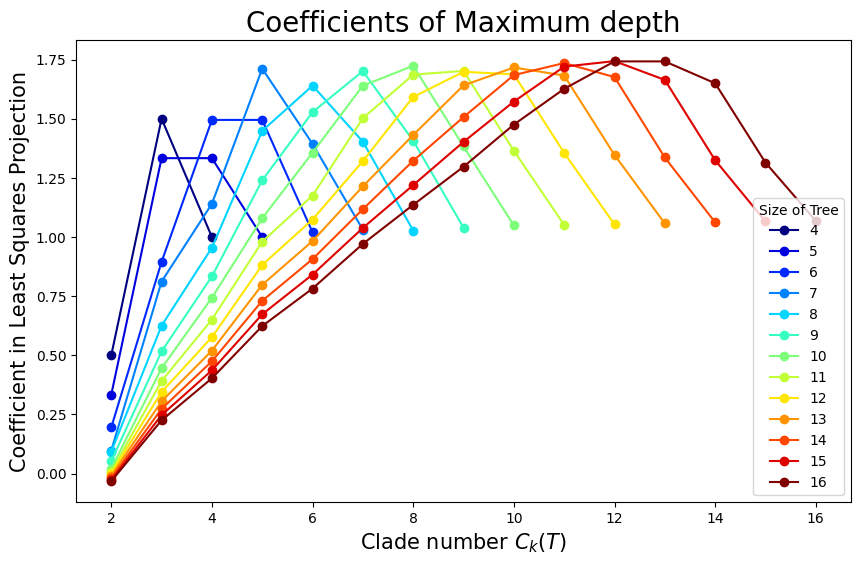

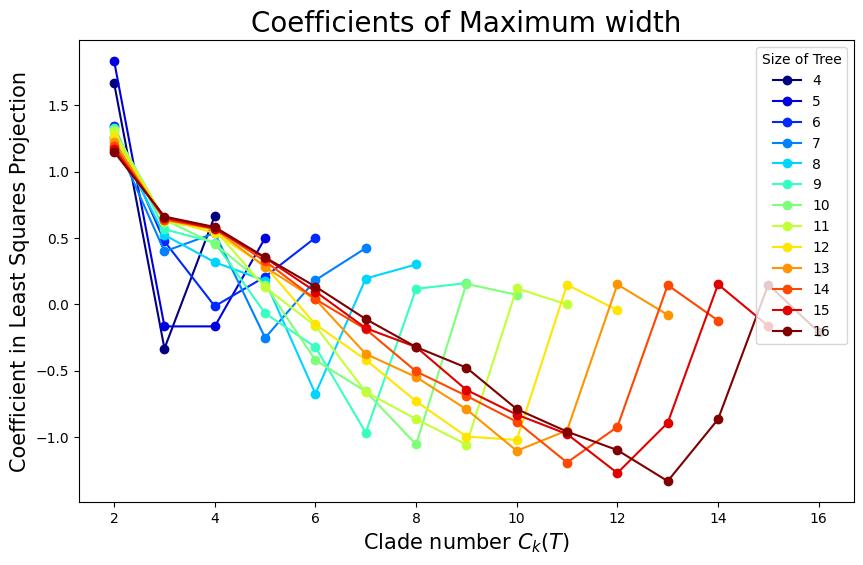

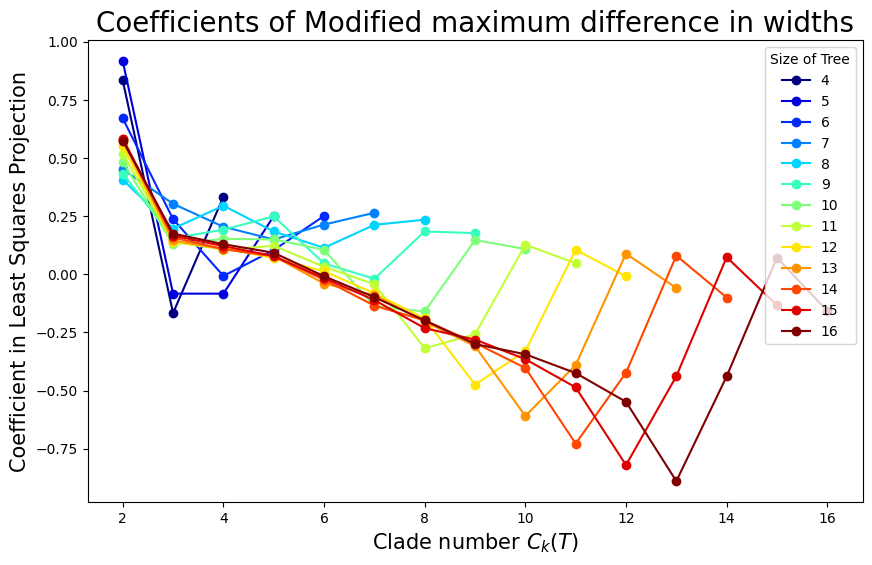

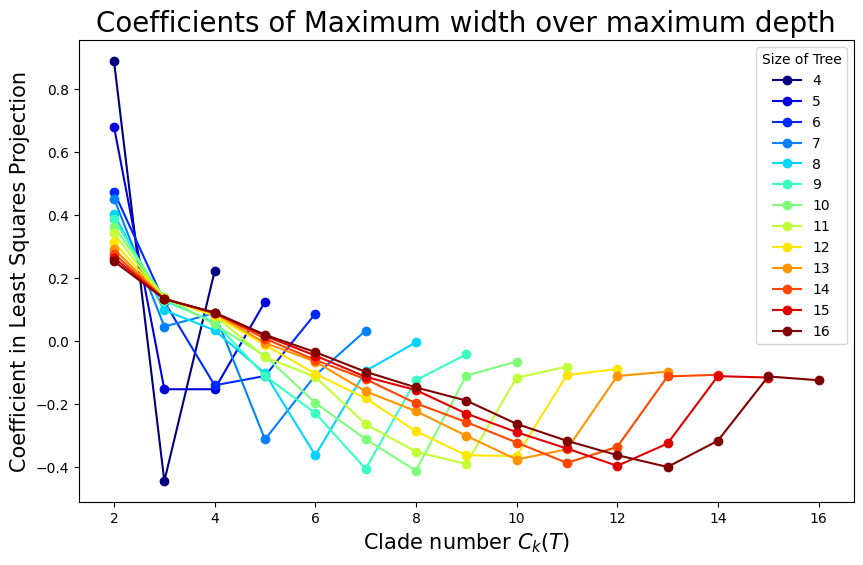

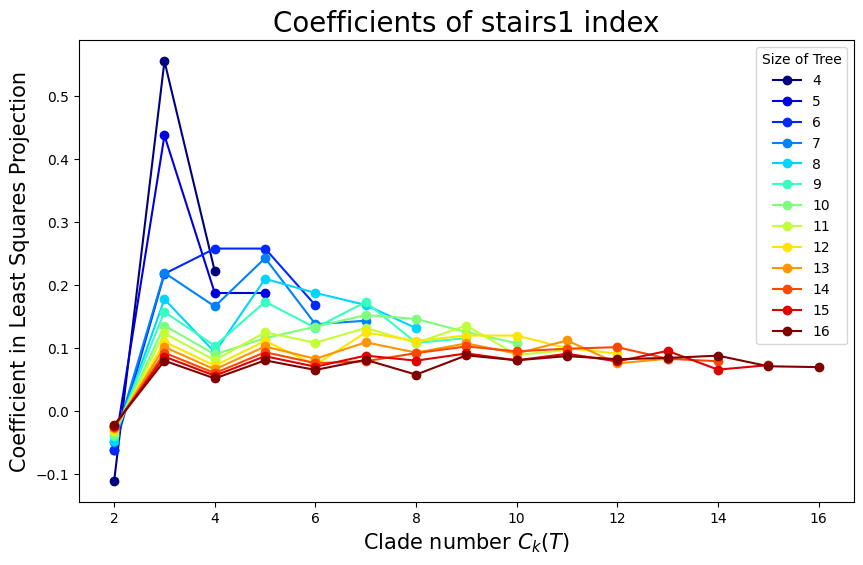

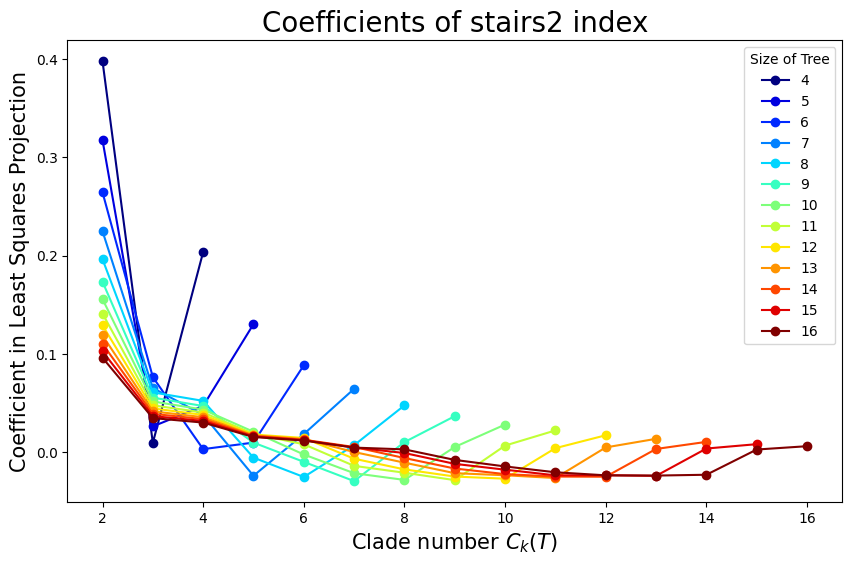

In [18]:
# Let's see the patterns in the coefficients for the clade numbers for every index
colors = plt.cm.jet(np.linspace(0,1,n-k0+1))
for index in clade_regression_results.keys():
    res = clade_regression_results[index]
    plt.figure(figsize=(10, 6))
    for k in range(k0, n+1):
        plt.plot(range(2, k+1), res[k-k0], 'o-', label=k, color=colors[k-k0])
    plt.xlabel('Clade number $C_k(T)$', fontsize = 15)
    plt.ylabel('Coefficient in Least Squares Projection', fontsize = 15)
    plt.title('Coefficients of ' + index, fontsize = 20)
    # Title the legend

    plt.legend(title="Size of Tree")

    plt.show()
